# Karar Eşiği, Olasılık Kalibrasyonu ve Hata Analizi (CIC-IDS2017)

> Açıklamalar Türkçedir; tablolar, grafikler ve sonuç dosyaları İngilizce hazırlanmıştır (ör. *Clean* = temiz test verisi, *Attacked* = uyarlamalı saldırgan altında).

**Neden bu notebook?** `00_cicids2017_robustness_experiments.ipynb`'de saldırı altında Recall belirgin biçimde düşerken PR-AUC ve ROC-AUC neredeyse hiç değişmiyordu. Bu, modellerin saldırı akışlarını hâlâ doğru *sıraladığını*, ancak skorlarının sabit 0.5 karar eşiğinin altına indiğini düşündürür. Bu notebook üç soruyu yanıtlar:

1. **Karar eşiği:** Eşik yalnızca doğrulama verisiyle seçildiğinde temiz veride ve saldırı altında Precision, Recall ve F1 nasıl değişir?
2. **Kalibrasyon:** Modellerin verdiği olasılıklar ne kadar güvenilir (Brier, ECE, log-loss)? Platt, isotonic ve temperature scaling bunu iyileştirir mi, saldırı altındaki başarıyı değiştirir mi?
3. **Hata analizi ve maliyet:** Saldırı altında hangi saldırı türleri kaçıyor, yanlış alarmlar nereden geliyor ve modellerin çıkarım (inference) süresi ne kadar?

**Protokol.** Veri, temizlik, modeller, test bölmesi ve saldırgan `00_cicids2017_robustness_experiments.ipynb` ile birebir aynıdır. Tek fark şudur: eşik ve kalibrasyon parametrelerini seçmek için her seed'in **eğitim kümesinden %10'luk bir doğrulama kümesi** ayrılır ve modeller kalan %90 ile eğitilir. Test verisi hiçbir seçim için kullanılmaz. Bu yüzden buradaki temel sonuçlar `00_cicids2017_robustness_experiments.ipynb`'dekilerden çok az farklı olabilir.

Saldırı senaryosu `00_cicids2017_robustness_experiments.ipynb`'deki referans senaryodur: uyarlamalı saldırgan, Boyut+Zaman, ε = %50. Bu notebook `00_cicids2017_robustness_experiments.ipynb`'den bağımsız çalışır; ham veriden başlar.

In [1]:
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.optimize import minimize_scalar

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix,
    brier_score_loss, log_loss, precision_recall_curve, roc_curve, average_precision_score,
)
from xgboost import XGBClassifier

In [2]:
DATA_DIR = Path("../data/raw/MachineLearningCVE")
GRAPHS_DIR = Path("../results/graphs/calibration")
METRICS_DIR = Path("../results/metrics/calibration")
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# 00_cicids2017_robustness_experiments.ipynb ile aynı ayarlar
SEEDS = [42, 100, 2024]
TEST_SIZE = 0.20
EPS_REF = 0.50
ADAPTIVE_GRID = 4
DECISION_THRESHOLD = 0.5
MODEL_NAMES = ["Random Forest", "XGBoost", "MLP"]

# Bu notebook'a özgü ayarlar
VAL_SIZE = 0.10              # eğitim kümesinden ayrılan doğrulama oranı (eşik ve kalibrasyon için)
FPR_BUDGET = 0.001           # "yanlış alarm bütçesi" politikası: doğrulamada en fazla %0.1 yanlış alarm
ECE_BINS = 15
TEMPERATURE_MODELS = ["XGBoost", "MLP"]   # logit çıktısı anlamlı olan modeller

In [3]:
# Grafik ve tablo stili (00_cicids2017_robustness_experiments.ipynb ile aynı)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
MODEL_COLORS = {"Random Forest": "#2a78d6", "XGBoost": "#eb6834", "MLP": "#1baf7a"}
METRIC_COLORS = {"Precision": "#6250d6", "Recall": "#eb6834", "F1": "#2a78d6"}
METHOD_COLORS = {"Uncalibrated": MUTED, "Platt": "#2a78d6", "Isotonic": "#eb6834", "Temperature": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 10, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

TABLE_STYLES = [
    {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; "
                                     "font-size: 13px; color: #0b0b0b; padding: 4px 0 8px 0;"},
    {"selector": "th", "props": "background: #f3f2ee; color: #0b0b0b; font-weight: 600; text-align: left; "
                                "padding: 6px 12px; border-bottom: 1px solid #c3c2b7;"},
    {"selector": "td", "props": "padding: 5px 12px; border-bottom: 1px solid #ecebe6; "
                                "font-variant-numeric: tabular-nums;"},
]


def save_fig(fig, name):
    fig.savefig(GRAPHS_DIR / f"{name}.png")
    plt.show()


def fig_title(fig, title, subtitle=None):
    h = fig.get_figheight()
    fig.text(0.01, 1 + 0.42 / h, title, ha="left", va="bottom", fontsize=12.5, fontweight="semibold")
    if subtitle:
        fig.text(0.01, 1 + 0.14 / h, subtitle, ha="left", va="bottom", fontsize=9.5, color=INK_2)


def top_legend(fig, handles, labels=None, **kwargs):
    h = fig.get_figheight()
    labels = labels if labels is not None else [hd.get_label() for hd in handles]
    fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.995, 1 + 0.36 / h),
               ncol=kwargs.pop("ncol", len(handles)), **kwargs)


def show_table(df, title, filename=None, precision=4):
    if filename:
        df.to_csv(METRICS_DIR / filename, index=False, encoding="utf-8-sig")
    styler = (df.style.set_caption(title).hide(axis="index")
              .set_table_styles(TABLE_STYLES).format(precision=precision, thousands=","))
    display(styler)


def format_pm(mean, std, digits=4):
    out = pd.DataFrame(index=mean.index)
    for col in mean.columns:
        d = digits.get(col, 4) if isinstance(digits, dict) else digits
        out[col] = [f"{m:,.{d}f} ± {s:,.{d}f}" for m, s in zip(mean[col], std[col].fillna(0))]
    return out

## 1. Veri: yükleme ve temizlik

`00_cicids2017_robustness_experiments.ipynb`'deki yükleme ve temizlik adımlarının birebir aynısıdır (sonsuz/eksik değerler, negatif değerler, sabit ve kopya sütunlar, Destination Port, etiket çakışmaları, tekrar eden satırlar). Sonuçta aynı 2,229,788 akış ve 64 özellik elde edilir; bu sayede seed'e göre yapılan eğitim–test bölmesi de `00_cicids2017_robustness_experiments.ipynb` ile aynıdır.

In [4]:
frames = []
for path in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    frames.append(df)
data = pd.concat(frames, ignore_index=True)
del frames
data["Label"] = (data["Label"].astype(str)
                 .str.replace("�", "-", regex=False)
                 .str.replace("\x96", "-", regex=False)
                 .str.strip())
INT_COLS_RAW = [c for c in data.columns if pd.api.types.is_integer_dtype(data[c])]

num_cols = data.columns.drop("Label")
data[num_cols] = data[num_cols].replace([np.inf, -np.inf], np.nan)
data = data.dropna()
nonneg_cols = [col for col in num_cols if not col.startswith("Init_Win_bytes")]
data = data[(data[nonneg_cols] >= 0).all(axis=1)]
data = data.drop(columns=[col for col in num_cols if data[col].nunique() <= 1])

seen, duplicate_cols = {}, []
for col in data.columns.drop("Label"):
    digest = hashlib.md5(pd.util.hash_pandas_object(data[col], index=False).values.tobytes()).hexdigest()
    if digest in seen and data[col].equals(data[seen[digest]]):
        duplicate_cols.append(col)
    else:
        seen.setdefault(digest, col)
data = data.drop(columns=duplicate_cols)

FEATURES = [col for col in data.columns if col not in ("Label", "Destination Port")]
data["Target"] = (data["Label"] != "BENIGN").astype("int8")
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
data = data[(data["Target"].groupby(row_hash.values).transform("nunique") == 1).values]
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
data = data[~row_hash.duplicated().values].reset_index(drop=True)

X = data[FEATURES].astype("float64")
y = data["Target"]
labels = data["Label"]
ports = data["Destination Port"]
INT_COLS = [col for col in FEATURES if col in INT_COLS_RAW]
del data
print(f"Son veri: {X.shape[0]:,} satır, {X.shape[1]} özellik · saldırı oranı %{y.mean() * 100:.2f}")

Son veri: 2,229,788 satır, 64 özellik · saldırı oranı %15.07


## 2. Modeller, pertürbasyon ve saldırgan

Model tanımları, özellik grupları, ağ kısıtlarını koruyan pertürbasyon ve uyarlamalı saldırgan `00_cicids2017_robustness_experiments.ipynb`'deki fonksiyonların aynısıdır. Tek ek şudur: uyarlamalı saldırgan, hata örneklerini gösterebilmek için her akış için seçtiği boyut (*s*) ve zaman (*t*) katsayılarını da döndürür.

In [5]:
def make_model(name, seed):
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed)
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=200, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", eval_metric="logloss", importance_type="gain", n_jobs=-1, random_state=seed,
        )
    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(64, 32), batch_size=1024, learning_rate_init=1e-3, max_iter=100,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, random_state=seed,
        )
    raise ValueError(name)


def split_data(seed):
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)


def present(columns):
    return [c for c in columns if c in FEATURES]


SIZE_FEATURES = present([
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
    "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
    "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std", "Packet Length Variance",
    "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size", "Subflow Fwd Bytes", "Subflow Bwd Bytes",
])
TIME_FEATURES = present([
    "Flow Duration",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Active Max", "Active Min",
    "Idle Mean", "Idle Std", "Idle Max", "Idle Min",
])
RATE_FEATURES = present(["Flow Bytes/s", "Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"])
FWD_SIZE_SCALED = present([
    "Total Length of Fwd Packets", "Fwd Packet Length Max", "Fwd Packet Length Min",
    "Fwd Packet Length Mean", "Fwd Packet Length Std", "Avg Fwd Segment Size", "Subflow Fwd Bytes",
])
BIDIR_SIZE_DERIVED = present(["Max Packet Length", "Packet Length Mean", "Average Packet Size"])
MODIFIED_FEATURES = FWD_SIZE_SCALED + BIDIR_SIZE_DERIVED + TIME_FEATURES + RATE_FEATURES


def max_allowed_factor(X_raw, columns, upper):
    if not columns:
        return np.full(len(X_raw), np.inf)
    values = X_raw[columns].to_numpy()
    limits = upper[columns].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(values > 0, limits / values, np.inf)
    return np.maximum(ratio.min(axis=1), 1.0)


def apply_perturbation(X_raw, size_factor, time_factor, bounds):
    lower, upper = bounds
    X_adv = X_raw.copy()
    n = len(X_adv)
    s = np.broadcast_to(np.asarray(size_factor, dtype=float), (n,)).copy()
    t = np.broadcast_to(np.asarray(time_factor, dtype=float), (n,)).copy()
    s = np.minimum(s, max_allowed_factor(X_adv, FWD_SIZE_SCALED, upper))
    t = np.minimum(t, max_allowed_factor(X_adv, TIME_FEATURES, upper))

    fwd_bytes_old = X_adv["Total Length of Fwd Packets"].to_numpy().copy()
    X_adv[FWD_SIZE_SCALED] = X_adv[FWD_SIZE_SCALED].to_numpy() * s[:, None]
    added_bytes = X_adv["Total Length of Fwd Packets"].to_numpy() - fwd_bytes_old

    n_packets = (X_adv["Total Fwd Packets"] + X_adv["Total Backward Packets"]).to_numpy()
    for col in present(["Packet Length Mean", "Average Packet Size"]):
        X_adv[col] = X_adv[col].to_numpy() + added_bytes / np.maximum(n_packets, 1)
    if "Max Packet Length" in X_adv:
        X_adv["Max Packet Length"] = np.maximum(X_adv["Max Packet Length"], X_adv["Fwd Packet Length Max"])

    T = X_adv[TIME_FEATURES].to_numpy()
    X_adv[TIME_FEATURES] = np.where(T > 0, T * t[:, None], T)

    total_bytes_old = fwd_bytes_old + X_adv["Total Length of Bwd Packets"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        byte_ratio = np.where(total_bytes_old > 0, (total_bytes_old + added_bytes) / total_bytes_old, 1.0)
    if "Flow Bytes/s" in X_adv:
        X_adv["Flow Bytes/s"] = X_adv["Flow Bytes/s"].to_numpy() * byte_ratio / t
    for col in present(["Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"]):
        X_adv[col] = X_adv[col].to_numpy() / t

    int_modified = [c for c in MODIFIED_FEATURES if c in INT_COLS]
    X_adv[int_modified] = np.round(X_adv[int_modified].to_numpy())
    X_adv[MODIFIED_FEATURES] = X_adv[MODIFIED_FEATURES].clip(
        lower=lower[MODIFIED_FEATURES], upper=upper[MODIFIED_FEATURES], axis=1
    )
    return X_adv


def adaptive_size_time(X_att, eps, bounds, score_fn):
    # 00_cicids2017_robustness_experiments.ipynb'deki uyarlamalı saldırganın Boyut+Zaman hâli; seçilen katsayıları da döndürür.
    levels = 1 + np.linspace(0, eps, ADAPTIVE_GRID)
    n = len(X_att)
    best_p, best_s, best_t = np.full(n, np.inf), np.ones(n), np.ones(n)
    for s in levels:
        for t in levels:
            p = score_fn(apply_perturbation(X_att, s, t, bounds))
            better = p < best_p
            best_p = np.where(better, p, best_p)
            best_s[better], best_t[better] = s, t
    return best_p, best_s, best_t

## 3. Kalibrasyon yöntemleri, kalibrasyon metrikleri ve eşik politikaları

**Kalibrasyon yöntemleri** (hepsi yalnızca doğrulama kümesinde öğrenilir):
- **Platt scaling:** Modelin skorunun logit'i üzerinde tek değişkenli lojistik regresyon (eğim + kesişim).
- **Isotonic regression:** Skoru gerçek saldırı oranına eşleyen, azalmayan basamaklı bir fonksiyon.
- **Temperature scaling:** Logit tek bir *T* sayısına bölünür (kesişim yok). Logit çıktısı anlamlı olan XGBoost ve MLP'ye uygulanır; Random Forest'ın skoru ağaç oylarının oranı olduğu için bu yönteme uygun değildir.

**Kalibrasyon metrikleri:** Brier skoru (olasılık ile gerçek etiket arasındaki ortalama kare hata), ECE (olasılıklar 15 aralığa bölünüp her aralıktaki ortalama olasılık ile gerçek saldırı oranı arasındaki farkın ağırlıklı ortalaması) ve log-loss. Üçünde de düşük değer daha iyidir.

**Eşik politikaları** (eşik doğrulama kümesinde seçilir, test kümesinde değerlendirilir):
- **Default 0.5:** `00_cicids2017_robustness_experiments.ipynb`'deki sabit eşik.
- **Val F1-max:** Doğrulama kümesinde F1'i en yüksek yapan eşik.
- **Val FPR ≤ 0.1%:** Doğrulama kümesinde yanlış alarm oranı %0.1'i geçmeyen en düşük eşik (en yüksek Recall). Gerçek IDS'lerde yanlış alarm bütçesine göre eşik seçmenin karşılığıdır.
- **Platt / Isotonic @ 0.5:** Kalibre edilmiş olasılık üzerinde 0.5 eşiği.

Önemli bir not: üç kalibrasyon yöntemi de skorun sırasını değiştirmeyen (azalmayan) dönüşümlerdir. Bu nedenle kalibrasyon ROC-AUC ve PR-AUC'yi değiştirmez; kalibre edilmiş olasılıkta 0.5 eşiği kullanmak, ham skorda farklı bir eşik kullanmakla aynı etkiyi yapar. Uyarlamalı saldırgan da skoru en aza indirdiği için seçtiği pertürbasyon kalibrasyondan etkilenmez.

In [6]:
EPS_CLIP = 1e-6


def logit(p):
    p = np.clip(p, EPS_CLIP, 1 - EPS_CLIP)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def fit_calibrators(name, p_val, y_val):
    # Doğrulama skorlarından kalibrasyon fonksiyonlarını öğrenir; {yöntem: fonksiyon} döndürür.
    calibrators = {"Uncalibrated": lambda p: p}
    platt = LogisticRegression(C=1e6).fit(logit(p_val).reshape(-1, 1), y_val)
    calibrators["Platt"] = lambda p, m=platt: m.predict_proba(logit(p).reshape(-1, 1))[:, 1]
    iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(p_val, y_val)
    calibrators["Isotonic"] = lambda p, m=iso: m.predict(p)
    if name in TEMPERATURE_MODELS:
        z_val = logit(p_val)
        res = minimize_scalar(lambda log_t: log_loss(y_val, sigmoid(z_val / np.exp(log_t)), labels=[0, 1]),
                              bounds=(-3, 3), method="bounded")
        temperature = float(np.exp(res.x))
        calibrators["Temperature"] = lambda p, T=temperature: sigmoid(logit(p) / T)
    return calibrators


def expected_calibration_error(y_true, p, n_bins=ECE_BINS):
    y_true = np.asarray(y_true)
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        mask = bins == b
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - p[mask].mean())
    return ece


def calibration_metrics(y_true, p):
    p = np.clip(p, EPS_CLIP, 1 - EPS_CLIP)
    return {"Brier": brier_score_loss(y_true, p), "ECE": expected_calibration_error(y_true, p),
            "Log-loss": log_loss(y_true, p, labels=[0, 1])}


def threshold_f1_max(y_val, p_val):
    precision, recall, thresholds = precision_recall_curve(y_val, p_val)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[np.argmax(f1)])


def threshold_fpr_budget(y_val, p_val, budget=FPR_BUDGET):
    fpr, tpr, thresholds = roc_curve(y_val, p_val)
    ok = np.where((fpr <= budget) & np.isfinite(thresholds))[0]
    return float(thresholds[ok[np.argmax(tpr[ok])]])


def metrics_at(y_true, p, threshold):
    y_true = np.asarray(y_true)
    y_pred = (p >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0), "FN": int(fn), "FP": int(fp)}

## 4. Ana döngü

Her seed için: 00 ile aynı eğitim–test bölmesi yapılır, eğitim kümesinden %10 doğrulama ayrılır, ölçekleyici ve model kalan %90 ile eğitilir. Ardından:
- doğrulama ve test skorları hesaplanır, çıkarım süresi ölçülür,
- uyarlamalı saldırgan (Boyut+Zaman, ε = `EPS_REF`) test kümesindeki saldırı akışlarına uygulanır,
- kalibrasyon yöntemleri ve eşikler doğrulama kümesinde öğrenilir, test kümesinde temiz ve saldırı altında değerlendirilir.

Çıkarım süresi, ölçeklenmiş test kümesinin tamamı için `predict_proba` süresinin akış başına düşen değeridir (mikrosaniye). Seed 42'nin skorları grafikler ve hata analizi için saklanır.

In [7]:
calibration_rows, threshold_rows, cost_rows = [], [], []
seed42 = {}
start = time.time()

for seed in SEEDS:
    X_tr_full, X_te, y_tr_full, y_te = split_data(seed)
    X_fit, X_val, y_fit, y_val = train_test_split(X_tr_full, y_tr_full, test_size=VAL_SIZE,
                                                  stratify=y_tr_full, random_state=seed)
    scaler = StandardScaler().fit(X_fit)
    Xs_fit = scaler.transform(X_fit).astype(np.float32)
    Xs_val = scaler.transform(X_val).astype(np.float32)
    Xs_te = scaler.transform(X_te).astype(np.float32)
    bounds = (X_fit.min(), X_fit.max())

    is_attack = (y_te == 1).to_numpy()
    X_att = X_te[is_attack]
    y_eval = np.r_[np.zeros((~is_attack).sum(), dtype=np.int8), np.ones(is_attack.sum(), dtype=np.int8)]
    y_val_np = y_val.to_numpy()

    for name in MODEL_NAMES:
        t0 = time.time()
        model = make_model(name, seed).fit(Xs_fit, y_fit.to_numpy())
        train_sec = time.time() - t0

        t1 = time.perf_counter()
        p_te = model.predict_proba(Xs_te)[:, 1]
        infer_us = (time.perf_counter() - t1) / len(Xs_te) * 1e6
        p_val = model.predict_proba(Xs_val)[:, 1]

        def score_fn(X_raw, model=model):
            return model.predict_proba(scaler.transform(X_raw).astype(np.float32))[:, 1]

        p_adv, s_chosen, t_chosen = adaptive_size_time(X_att, EPS_REF, bounds, score_fn)
        p_benign = p_te[~is_attack]
        p_clean_eval = np.r_[p_benign, p_te[is_attack]]
        p_adv_eval = np.r_[p_benign, p_adv]

        cost_rows.append({"Seed": seed, "Model": name, "Training time (s)": train_sec,
                          "Inference (µs / flow)": infer_us,
                          "Throughput (flows / s)": 1e6 / infer_us})

        # Kalibrasyon: yalnızca doğrulama kümesinde öğrenilir, temiz test verisinde ölçülür
        calibrators = fit_calibrators(name, p_val, y_val_np)
        for method, f in calibrators.items():
            calibration_rows.append({"Seed": seed, "Model": name, "Method": method,
                                     **calibration_metrics(y_te, f(p_te))})

        # Eşik politikaları: ham skor üzerinde doğrulamadan seçilen eşikler + kalibre olasılıkta 0.5
        policies = {
            "Default 0.5": (calibrators["Uncalibrated"], DECISION_THRESHOLD),
            "Val F1-max": (calibrators["Uncalibrated"], threshold_f1_max(y_val_np, p_val)),
            "Val FPR ≤ 0.1%": (calibrators["Uncalibrated"], threshold_fpr_budget(y_val_np, p_val)),
            "Platt @ 0.5": (calibrators["Platt"], DECISION_THRESHOLD),
            "Isotonic @ 0.5": (calibrators["Isotonic"], DECISION_THRESHOLD),
        }
        for policy, (f, thr) in policies.items():
            clean_m = metrics_at(y_eval, f(p_clean_eval), thr)
            adv_m = metrics_at(y_eval, f(p_adv_eval), thr)
            threshold_rows.append({"Seed": seed, "Model": name, "Policy": policy, "Threshold": thr,
                                   **{f"{k} (clean)": v for k, v in clean_m.items()},
                                   **{f"{k} (attacked)": v for k, v in adv_m.items()}})

        if seed == SEEDS[0]:
            seed42[name] = {"p_val": p_val, "y_val": y_val_np, "p_clean": p_clean_eval, "p_adv": p_adv_eval,
                            "y_eval": y_eval, "p_te": p_te, "s": s_chosen, "t": t_chosen,
                            "calibrators": calibrators,
                            "thresholds": {k: v[1] for k, v in policies.items() if k.startswith("Val")}}
        print(f"seed {seed:<5} {name:<14} tamamlandı  ({time.time() - t0:,.0f} sn)")
        del model

    if seed == SEEDS[0]:
        X_te42, y_te42, X_att42, bounds42 = X_te, y_te, X_att, bounds

calibration_df = pd.DataFrame(calibration_rows)
threshold_df = pd.DataFrame(threshold_rows)
cost_df = pd.DataFrame(cost_rows)
calibration_df.to_csv(METRICS_DIR / "raw_calibration_per_seed.csv", index=False, encoding="utf-8-sig")
threshold_df.to_csv(METRICS_DIR / "raw_threshold_policies_per_seed.csv", index=False, encoding="utf-8-sig")
cost_df.to_csv(METRICS_DIR / "raw_cost_per_seed.csv", index=False, encoding="utf-8-sig")
print(f"\nToplam süre: {(time.time() - start) / 60:,.1f} dk")

seed 42    Random Forest  tamamlandı  (121 sn)


seed 42    XGBoost        tamamlandı  (31 sn)


seed 42    MLP            tamamlandı  (47 sn)


seed 100   Random Forest  tamamlandı  (123 sn)


seed 100   XGBoost        tamamlandı  (32 sn)


seed 100   MLP            tamamlandı  (80 sn)


seed 2024  Random Forest  tamamlandı  (115 sn)


seed 2024  XGBoost        tamamlandı  (31 sn)


seed 2024  MLP            tamamlandı  (71 sn)

Toplam süre: 11.1 dk


## 5. Sonuçlar: kalibrasyon

In [8]:
g = calibration_df.groupby(["Model", "Method"], sort=False)[["Brier", "ECE", "Log-loss"]]
calib_table = format_pm(g.mean(), g.std(), digits=5).reset_index()
show_table(calib_table, f"Table C1 — Calibration on clean test data ({len(SEEDS)} seeds, mean ± std; lower is better)",
           "calibration_metrics.csv")

Model,Method,Brier,ECE,Log-loss
Random Forest,Uncalibrated,0.00068 ± 0.00003,0.00068 ± 0.00002,0.00289 ± 0.00009
Random Forest,Platt,0.00065 ± 0.00003,0.00020 ± 0.00003,0.00261 ± 0.00011
Random Forest,Isotonic,0.00065 ± 0.00003,0.00016 ± 0.00007,0.00259 ± 0.00016
XGBoost,Uncalibrated,0.00045 ± 0.00003,0.00015 ± 0.00001,0.00171 ± 0.00012
XGBoost,Platt,0.00045 ± 0.00003,0.00013 ± 0.00003,0.00171 ± 0.00013
XGBoost,Isotonic,0.00046 ± 0.00003,0.00013 ± 0.00004,0.00181 ± 0.00021
XGBoost,Temperature,0.00045 ± 0.00003,0.00013 ± 0.00002,0.00171 ± 0.00014
MLP,Uncalibrated,0.00325 ± 0.00016,0.00154 ± 0.00028,0.01204 ± 0.00082
MLP,Platt,0.00322 ± 0.00015,0.00120 ± 0.00044,0.01196 ± 0.00078
MLP,Isotonic,0.00307 ± 0.00026,0.00034 ± 0.00006,0.01155 ± 0.00100


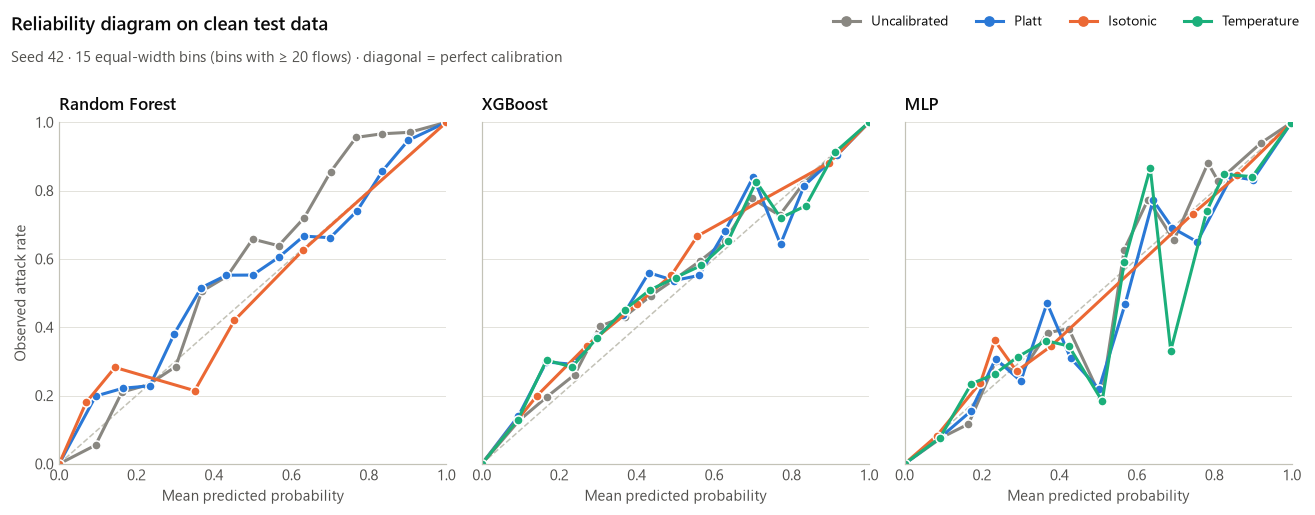

In [9]:
# Güvenilirlik diyagramı (seed 42, temiz test verisi)
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(12, 4), sharey=True)
edges = np.linspace(0, 1, ECE_BINS + 1)
for ax, name in zip(axes, MODEL_NAMES):
    d = seed42[name]
    y_true = d["y_eval"]
    ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, linestyle="--")
    for method, f in d["calibrators"].items():
        p = f(d["p_clean"])
        idx = np.minimum(np.digitize(p, edges) - 1, ECE_BINS - 1)
        xs, ys = [], []
        for b in range(ECE_BINS):
            mask = idx == b
            if mask.sum() >= 20:
                xs.append(p[mask].mean()); ys.append(y_true[mask].mean())
        ax.plot(xs, ys, marker="o", color=METHOD_COLORS[method], markeredgecolor="white", markeredgewidth=1,
                label=method)
    ax.set_title(name)
    ax.set_xlabel("Mean predicted probability")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("Observed attack rate")
fig.tight_layout()
top_legend(fig, [Line2D([], [], color=c, marker="o", label=m) for m, c in METHOD_COLORS.items()])
fig_title(fig, "Reliability diagram on clean test data",
          f"Seed {SEEDS[0]} · {ECE_BINS} equal-width bins (bins with ≥ 20 flows) · diagonal = perfect calibration")
save_fig(fig, "C1_reliability_diagram")

## 6. Sonuçlar: karar eşiği

In [10]:
cols = ["Threshold", "Precision (clean)", "Recall (clean)", "F1 (clean)", "FP (clean)",
        "Recall (attacked)", "F1 (attacked)", "FN (attacked)"]
g = threshold_df.groupby(["Model", "Policy"], sort=False)[cols]
thr_table = format_pm(g.mean(), g.std(), digits={**{c: 4 for c in cols}, "FP (clean)": 0, "FN (attacked)": 0})
show_table(thr_table.reset_index(),
           f"Table C2 — Threshold policies: clean vs. adaptive attack (Size+Time, ε = {EPS_REF * 100:.0f}%; "
           f"{len(SEEDS)} seeds, mean ± std)", "threshold_policies.csv")

Model,Policy,Threshold,Precision (clean),Recall (clean),F1 (clean),FP (clean),Recall (attacked),F1 (attacked),FN (attacked)
Random Forest,Default 0.5,0.5000 ± 0.0000,0.9983 ± 0.0001,0.9958 ± 0.0004,0.9971 ± 0.0002,112 ± 9,0.9132 ± 0.0178,0.9537 ± 0.0097,"5,834 ± 1,197"
Random Forest,Val F1-max,0.4115 ± 0.0323,0.9975 ± 0.0003,0.9968 ± 0.0001,0.9972 ± 0.0001,168 ± 22,0.9602 ± 0.0077,0.9784 ± 0.0038,"2,675 ± 516"
Random Forest,Val FPR ≤ 0.1%,0.2438 ± 0.0083,0.9947 ± 0.0004,0.9984 ± 0.0004,0.9965 ± 0.0001,360 ± 31,0.9798 ± 0.0006,0.9871 ± 0.0002,"1,358 ± 42"
Random Forest,Platt @ 0.5,0.5000 ± 0.0000,0.9979 ± 0.0003,0.9963 ± 0.0005,0.9971 ± 0.0001,139 ± 18,0.9326 ± 0.0252,0.9640 ± 0.0135,"4,530 ± 1,692"
Random Forest,Isotonic @ 0.5,0.5000 ± 0.0000,0.9975 ± 0.0003,0.9968 ± 0.0001,0.9972 ± 0.0001,168 ± 23,0.9602 ± 0.0077,0.9784 ± 0.0038,"2,675 ± 516"
XGBoost,Default 0.5,0.5000 ± 0.0000,0.9982 ± 0.0001,0.9977 ± 0.0003,0.9980 ± 0.0002,120 ± 9,0.9785 ± 0.0016,0.9883 ± 0.0008,"1,444 ± 111"
XGBoost,Val F1-max,0.5532 ± 0.1165,0.9982 ± 0.0006,0.9976 ± 0.0007,0.9979 ± 0.0001,119 ± 43,0.9774 ± 0.0024,0.9877 ± 0.0009,"1,518 ± 158"
XGBoost,Val FPR ≤ 0.1%,0.1347 ± 0.0231,0.9949 ± 0.0003,0.9995 ± 0.0001,0.9972 ± 0.0001,345 ± 23,0.9835 ± 0.0002,0.9891 ± 0.0003,"1,106 ± 15"
XGBoost,Platt @ 0.5,0.5000 ± 0.0000,0.9983 ± 0.0001,0.9977 ± 0.0004,0.9980 ± 0.0002,114 ± 10,0.9782 ± 0.0016,0.9881 ± 0.0008,"1,463 ± 108"
XGBoost,Isotonic @ 0.5,0.5000 ± 0.0000,0.9982 ± 0.0006,0.9976 ± 0.0007,0.9979 ± 0.0001,119 ± 43,0.9775 ± 0.0023,0.9878 ± 0.0009,"1,509 ± 156"


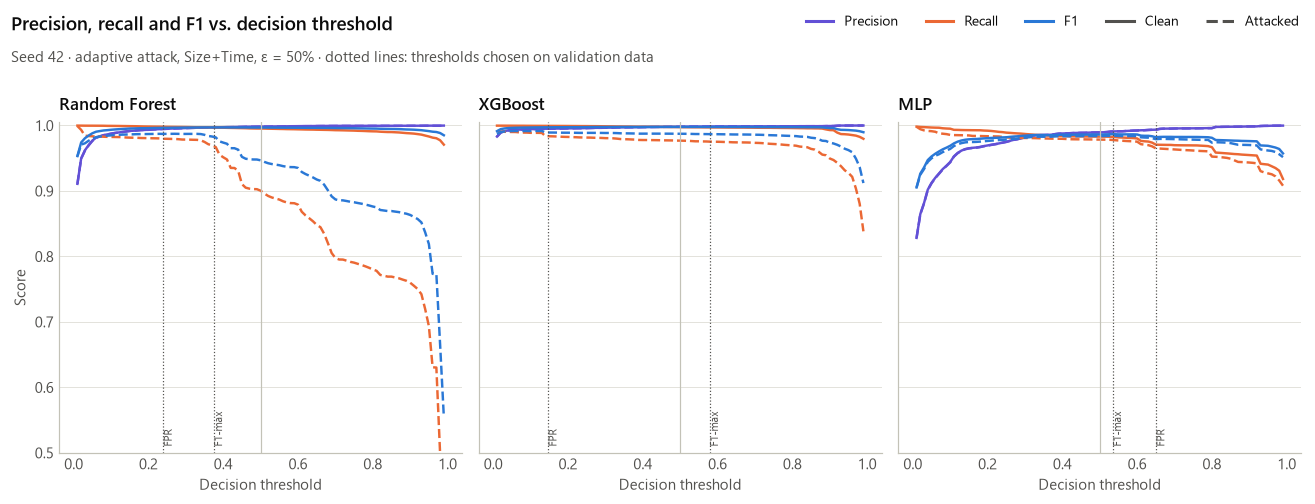

In [11]:
# Eşiğe göre Precision / Recall / F1: temiz (düz çizgi) ve saldırı altında (kesikli), seed 42
grid = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(12, 3.9), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = seed42[name]
    for metric, fn in [("Precision", precision_score), ("Recall", recall_score), ("F1", f1_score)]:
        for p, style in [(d["p_clean"], "-"), (d["p_adv"], "--")]:
            vals = [fn(d["y_eval"], (p >= thr).astype(np.int8), zero_division=0) for thr in grid]
            ax.plot(grid, vals, color=METRIC_COLORS[metric], linestyle=style, linewidth=1.6)
    for policy, thr in d["thresholds"].items():
        ax.axvline(thr, color=INK_2, linewidth=0.8, linestyle=":")
        ax.text(thr, 0.505, " F1-max" if "F1" in policy else " FPR", fontsize=7.5, color=INK_2, rotation=90,
                va="bottom")
    ax.axvline(DECISION_THRESHOLD, color=AXIS, linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Decision threshold")
    ax.set_ylim(0.5, 1.005)
axes[0].set_ylabel("Score")
fig.tight_layout()
handles = [Line2D([], [], color=c, label=m) for m, c in METRIC_COLORS.items()]
handles += [Line2D([], [], color=INK_2, linestyle="-", label="Clean"),
            Line2D([], [], color=INK_2, linestyle="--", label="Attacked")]
top_legend(fig, handles)
fig_title(fig, "Precision, recall and F1 vs. decision threshold",
          f"Seed {SEEDS[0]} · adaptive attack, Size+Time, ε = {EPS_REF * 100:.0f}% · "
          "dotted lines: thresholds chosen on validation data")
save_fig(fig, "C2_threshold_curves")

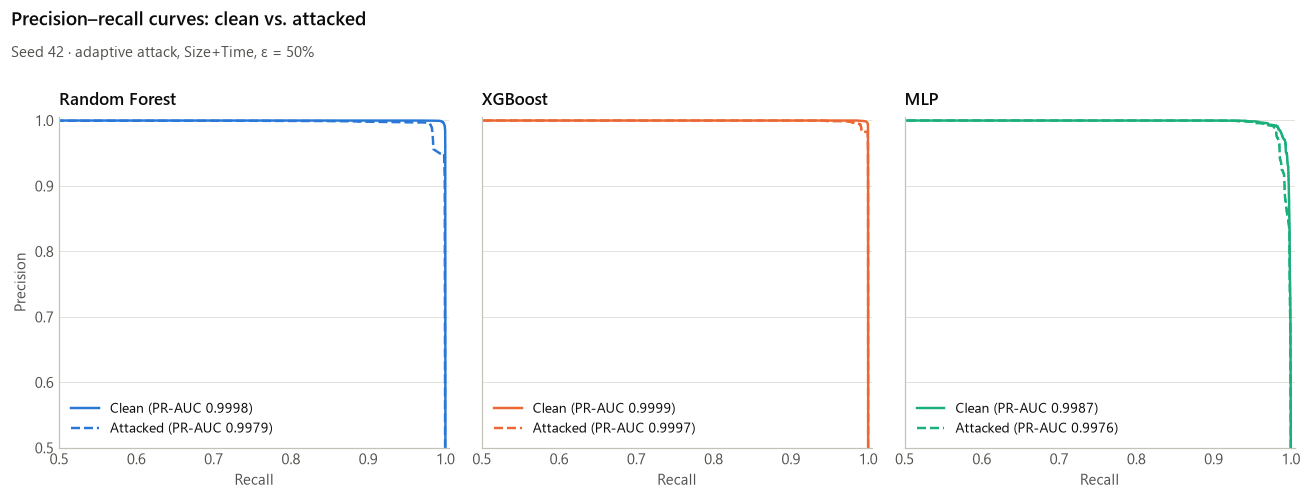

In [12]:
# Precision–Recall eğrileri: temiz ve saldırı altında (seed 42)
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(12, 3.9), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = seed42[name]
    for p, style, label in [(d["p_clean"], "-", "Clean"), (d["p_adv"], "--", "Attacked")]:
        precision, recall, _ = precision_recall_curve(d["y_eval"], p)
        ap = average_precision_score(d["y_eval"], p)
        ax.plot(recall, precision, color=MODEL_COLORS[name], linestyle=style, linewidth=1.6,
                label=f"{label} (PR-AUC {ap:.4f})")
    ax.set_title(name)
    ax.set_xlabel("Recall")
    ax.set_xlim(0.5, 1.005); ax.set_ylim(0.5, 1.005)
    ax.legend(loc="lower left")
axes[0].set_ylabel("Precision")
fig.tight_layout()
fig_title(fig, "Precision–recall curves: clean vs. attacked",
          f"Seed {SEEDS[0]} · adaptive attack, Size+Time, ε = {EPS_REF * 100:.0f}%")
save_fig(fig, "C3_pr_curves")

## 7. Hata analizi (seed 42, varsayılan eşik 0.5)

Üç soru incelenir:
1. **Yanlış negatifler:** Saldırı altında hangi saldırı türleri kaçıyor? Her tür için temiz ve saldırı altındaki Recall karşılaştırılır.
2. **Örnek akışlar:** Uyarlamalı saldırganın XGBoost'tan kaçırdığı akışlardan, en çok kaçan türlerin her birinden bir örnek: saldırganın seçtiği katsayılar ve temel özelliklerin önceki/sonraki değerleri.
3. **Yanlış pozitifler:** Normal trafiğe dokunulmadığı için yanlış alarmlar saldırıdan etkilenmez. Yine de nereden geldikleri (hedef port) ve modellerin aynı akışlarda mı hata yaptığı incelenir.

In [13]:
attack_labels = labels.loc[X_att42.index]
per_type = pd.DataFrame({"Count in test": attack_labels.value_counts()})
for name in MODEL_NAMES:
    d = seed42[name]
    n_benign = int((d["y_eval"] == 0).sum())
    det_clean = pd.Series(d["p_clean"][n_benign:] >= DECISION_THRESHOLD, index=X_att42.index)
    det_adv = pd.Series(d["p_adv"][n_benign:] >= DECISION_THRESHOLD, index=X_att42.index)
    per_type[f"{name} · clean"] = det_clean.groupby(attack_labels).mean()
    per_type[f"{name} · attacked"] = det_adv.groupby(attack_labels).mean()
    per_type[f"{name} · missed (attacked)"] = (~det_adv).groupby(attack_labels).sum()

per_type = per_type.sort_values("Count in test", ascending=False)
show_table(per_type.reset_index(names="Attack type"),
           f"Table C3 — Recall per attack type, clean vs. adaptive attack (seed {SEEDS[0]}, Size+Time, "
           f"ε = {EPS_REF * 100:.0f}%, threshold {DECISION_THRESHOLD})", "error_recall_per_attack_type.csv", precision=3)

for name in MODEL_NAMES:
    missed = per_type[f"{name} · missed (attacked)"]
    top = (missed / missed.sum() * 100).sort_values(ascending=False).head(3)
    print(f"{name:<14} saldırı altında kaçan {int(missed.sum()):,} akışın en büyük payları: "
          + ", ".join(f"{k} %{v:.1f}" for k, v in top.items()))

Attack type,Count in test,Random Forest · clean,Random Forest · attacked,Random Forest · missed (attacked),XGBoost · clean,XGBoost · attacked,XGBoost · missed (attacked),MLP · clean,MLP · attacked,MLP · missed (attacked)
DoS Hulk,"34,447",0.996,0.989,372,0.999,0.997,92,0.986,0.985,500
DDoS,"25,786",0.999,0.813,"4,817",1.000,0.986,356,0.999,0.999,31
DoS GoldenEye,"2,009",0.998,0.976,48,0.998,0.997,6,0.988,0.967,67
FTP-Patator,"1,184",0.999,0.866,159,0.999,0.997,3,0.992,0.984,19
DoS slowloris,"1,050",0.996,0.676,340,0.996,0.682,334,0.993,0.957,45
DoS Slowhttptest,"1,017",0.992,0.385,625,0.998,0.423,587,0.992,0.964,37
SSH-Patator,626,0.978,0.936,40,0.992,0.986,9,0.922,0.917,52
PortScan,399,0.992,0.955,18,0.995,0.985,6,0.950,0.890,44
Bot,286,0.608,0.189,232,0.626,0.524,136,0.476,0.045,273
Web Attack - Brute Force,279,0.968,0.907,26,0.975,0.961,11,0.075,0.057,263


Random Forest  saldırı altında kaçan 6,694 akışın en büyük payları: DDoS %72.0, DoS Slowhttptest %9.3, DoS Hulk %5.6
XGBoost        saldırı altında kaçan 1,554 akışın en büyük payları: DoS Slowhttptest %37.8, DDoS %22.9, DoS slowloris %21.5
MLP            saldırı altında kaçan 1,447 akışın en büyük payları: DoS Hulk %34.6, Bot %18.9, Web Attack - Brute Force %18.2


In [14]:
# Örnek kaçan akışlar: XGBoost, en çok kaçan türlerden birer örnek
d = seed42["XGBoost"]
n_benign = int((d["y_eval"] == 0).sum())
p_before, p_after = d["p_clean"][n_benign:], d["p_adv"][n_benign:]
escaped = (p_before >= DECISION_THRESHOLD) & (p_after < DECISION_THRESHOLD)
escaped_types = attack_labels[escaped].value_counts().head(4).index

SHOW_COLS = ["Fwd Packet Length Mean", "Total Length of Fwd Packets", "Flow Duration", "Flow Bytes/s"]
example_rows = []
for attack in escaped_types:
    pos = np.where(escaped & (attack_labels == attack).to_numpy())[0][0]
    flow = X_att42.iloc[[pos]]
    adv = apply_perturbation(flow, d["s"][pos], d["t"][pos], bounds42)
    row = {"Attack type": attack, "s (size)": d["s"][pos], "t (time)": d["t"][pos],
           "p(attack) before": p_before[pos], "p(attack) after": p_after[pos]}
    for c in SHOW_COLS:
        row[c] = f"{flow[c].iloc[0]:,.0f} → {adv[c].iloc[0]:,.0f}"
    example_rows.append(row)
show_table(pd.DataFrame(example_rows),
           f"Table C4 — Example flows evading XGBoost under the adaptive attack (seed {SEEDS[0]}; "
           "factors are capped by the training range)", "error_example_flows.csv", precision=3)

Attack type,s (size),t (time),p(attack) before,p(attack) after,Fwd Packet Length Mean,Total Length of Fwd Packets,Flow Duration,Flow Bytes/s
DoS Slowhttptest,1.000,1.167,0.927,0.010,0 → 0,0 → 0,"63,138,823 → 73,661,960",0 → 0
DDoS,1.333,1.500,0.999,0.181,6 → 8,30 → 40,"37,996 → 56,994",790 → 702
DoS slowloris,1.000,1.167,0.998,0.134,0 → 0,0 → 0,"3,002,703 → 3,503,154",0 → 0
DoS Hulk,1.000,1.500,0.924,0.178,0 → 0,0 → 0,"866 → 1,299",0 → 0


In [15]:
# Yanlış pozitifler: hangi hedef portlardan geliyor, modeller aynı akışlarda mı hata yapıyor?
benign_idx = X_te42.index[(y_te42 == 0).to_numpy()]
fp_sets, fp_rows = {}, []
for name in MODEL_NAMES:
    d = seed42[name]
    n_benign = int((d["y_eval"] == 0).sum())
    fp_mask = d["p_clean"][:n_benign] >= DECISION_THRESHOLD
    fp_idx = benign_idx[fp_mask]
    fp_sets[name] = set(fp_idx)
    share = ports.loc[fp_idx].value_counts(normalize=True).head(3) * 100
    benign_share = ports.loc[benign_idx].value_counts(normalize=True) * 100
    fp_rows.append({"Model": name, "FP": len(fp_idx),
                    "FP rate (%)": len(fp_idx) / n_benign * 100,
                    "Top destination ports of FPs (share; share among all benign)":
                        ", ".join(f"{int(p)} ({s:.0f}%; {benign_share.get(p, 0):.0f}%)" for p, s in share.items())})
common = set.intersection(*fp_sets.values())
fp_table = pd.DataFrame(fp_rows)
show_table(fp_table, f"Table C5 — False positives on clean test data (seed {SEEDS[0]}, threshold {DECISION_THRESHOLD})",
           "error_false_positives.csv", precision=3)
print(f"Üç modelin ortak yanlış alarmı: {len(common):,} akış "
      f"(RF FP'lerinin %{len(common) / max(len(fp_sets['Random Forest']), 1) * 100:.0f}'i, "
      f"XGBoost FP'lerinin %{len(common) / max(len(fp_sets['XGBoost']), 1) * 100:.0f}'i)")

Model,FP,FP rate (%),Top destination ports of FPs (share; share among all benign)
Random Forest,109,0.029,"443 (58%; 24%), 8080 (31%; 0%), 80 (9%; 11%)"
XGBoost,124,0.033,"443 (45%; 24%), 80 (28%; 11%), 8080 (17%; 0%)"
MLP,699,0.185,"443 (80%; 24%), 80 (6%; 11%), 1 (1%; 0%)"


Üç modelin ortak yanlış alarmı: 50 akış (RF FP'lerinin %46'i, XGBoost FP'lerinin %40'i)


## 8. Hesaplama maliyeti

In [16]:
g = cost_df.groupby("Model")[["Training time (s)", "Inference (µs / flow)", "Throughput (flows / s)"]]
cost_table = format_pm(g.mean().loc[MODEL_NAMES], g.std().loc[MODEL_NAMES],
                       digits={"Training time (s)": 1, "Inference (µs / flow)": 2,
                               "Throughput (flows / s)": 0}).reset_index()
show_table(cost_table, f"Table C6 — Training and inference cost ({len(SEEDS)} seeds, mean ± std; "
           f"{int(len(X) * (1 - TEST_SIZE) * (1 - VAL_SIZE)):,} training flows)", "cost.csv")

Model,Training time (s),Inference (µs / flow),Throughput (flows / s)
Random Forest,113.1 ± 4.3,1.54 ± 0.04,"649,036 ± 18,497"
XGBoost,24.9 ± 0.3,0.79 ± 0.04,"1,260,260 ± 64,074"
MLP,60.7 ± 17.0,0.19 ± 0.01,"5,189,156 ± 231,563"


### Yorumlar

Aşağıdaki değerler, aksi belirtilmedikçe 3 seed ortalamasıdır. Hata analizi tabloları (C3–C5) seed 42 içindir.

**1. Kalibrasyon: modeller temiz veride zaten iyi kalibre.**
Temiz test verisinde ECE değerleri 0.0002–0.0015 arasındadır (Tablo C1). En iyi kalibre model XGBoost'tur ve kalibrasyon yöntemleri onu neredeyse hiç değiştirmez. Random Forest'ta Platt ve isotonic ECE'yi yaklaşık üçte bire indirir (0.00068 → 0.00016–0.00020). MLP'de en büyük iyileşmeyi isotonic sağlar (0.00154 → 0.00034); temperature scaling ise etkisizdir. Yani bu veri setinde kalibrasyon sorunu, saldırı altındaki kaybı açıklayacak büyüklükte değildir.

**2. Karar eşiği: Random Forest'ın kaybının büyük kısmı eşik kaynaklı.**
Saldırı altında en çok kaybeden model olan Random Forest'ta eşik seçimi sonucu belirgin biçimde değiştirmektedir (Tablo C2, Grafik C2):
- Sabit 0.5 eşiğiyle saldırı altında 5,834 saldırı kaçmaktadır.
- Doğrulamada F1'i en yüksek yapan eşikle (≈0.41) bu sayı 2,675'e iner (%54 azalma).
- Doğrulamada yanlış alarm oranını %0.1 ile sınırlayan eşikle (≈0.24) 1,358'e iner (%77 azalma). Bunun bedeli temiz veride yanlış alarm sayısının 112'den 360'a çıkmasıdır; bu da normal trafiğin yalnızca %0.1'idir. Temiz F1 neredeyse değişmez (0.9971 → 0.9965).

Grafik C2 nedenini göstermektedir: saldırı altında Random Forest'ın Recall eğrisi 0.5 civarında hızla düşer, 0.3'ün altında ise neredeyse temiz verideki düzeye yaklaşır. Uyarlamalı saldırgan Random Forest'ın skorunu 0.5'in hemen altına itebilmekte, ancak çok daha aşağıya indirememektedir. Random Forest'ın skoru ağaç oylarının oranı olduğu için oyların birkaçını değiştirmek eşiği geçmeye yetmektedir.

XGBoost'ta etki daha küçüktür (yanlış alarm bütçesi eşiğiyle kaçan saldırılar 1,444 → 1,106, %23 azalma). MLP'de ise aynı politika eşiği 0.5'in üzerine çıkarır (≈0.70) ve kaçan saldırı sayısını artırır, çünkü MLP temiz veride zaten çok sayıda yanlış alarm üretmektedir.

Bu sonuç, `00_cicids2017_robustness_experiments.ipynb`'deki dayanıklılık sıralamasının sabit 0.5 eşiğine bağlı olduğunu gösterir. Yanlış alarm bütçesine göre seçilen eşikle saldırı altındaki F1 değerleri Random Forest 0.9871, XGBoost 0.9891, MLP 0.9761'dir; yani Random Forest ile XGBoost arasındaki fark büyük ölçüde kapanır.

**3. Kalibrasyon saldırı altındaki başarıyı neden değiştirmiyor?**
Üç kalibrasyon yöntemi de skorun sırasını korur. Bu yüzden kalibre edilmiş olasılıkta 0.5 eşiği kullanmak, ham skorda başka bir eşik kullanmakla aynıdır: örneğin Random Forest'ta "Isotonic @ 0.5" satırı, "Val F1-max" satırıyla birebir aynıdır. Kalibrasyonun saldırı altındaki etkisi tamamen bu örtük eşik değişiminden gelir; olasılıkların daha "doğru" olması tek başına dayanıklılık sağlamaz.

**4. Hata analizi: kaçan saldırılar modele göre farklı türlerden geliyor.**
- **Random Forest:** Saldırı altında kaçan akışların %72'si DDoS'tur (Recall 0.9995 → 0.813). Yavaş DoS türleri de belirgin biçimde etkilenir (Slowhttptest 0.99 → 0.39, slowloris 0.996 → 0.68).
- **XGBoost:** Kaçanların çoğu yavaş DoS türleridir (Slowhttptest %38, slowloris %22). DDoS'ta Recall 0.986'da kalır.
- **MLP:** Saldırı altındaki kayıp küçüktür, ancak MLP bazı türleri temiz veride bile tanıyamamaktadır: Web Attack – Brute Force (0.075), XSS (0.028) ve Bot (0.48). MLP'nin temiz verideki yüksek FN sayısının kaynağı budur.

Tablo C4'teki örnekler saldırganın ne yaptığını somut olarak gösterir. Örneğin ileri yönde hiç veri taşımayan bir DoS Slowhttptest akışı, yalnızca süresi 63.1 saniyeden 73.7 saniyeye uzatıldığında XGBoost'un saldırı olasılığı 0.93'ten 0.01'e düşmektedir. Bu, `00_cicids2017_robustness_experiments.ipynb`'de bulunan "yavaş DoS saldırıları sabit bir süre imzasıyla tanınıyor" sonucunu doğrudan örnekler.

**5. Yanlış alarmlar.**
Normal trafiğe dokunulmadığı için yanlış alarmlar saldırıdan etkilenmez. Temiz veride yanlış alarm oranı ağaç modellerinde %0.03, MLP'de %0.18'dir (Tablo C5). Yanlış alarmlar 443 (HTTPS) ve 8080 portlarında yoğunlaşmaktadır: örneğin Random Forest'ın yanlış alarmlarının %58'i port 443'tendir, oysa bu port normal trafiğin %24'ünü oluşturur. Üç modelin 50 yanlış alarmı ortaktır; bu, ağaç modellerinin yanlış alarmlarının yaklaşık %40–46'sıdır. Farklı karar mantığına sahip üç modelin aynı akışlarda yanılması, bu akışların bir kısmının saldırı trafiğine çok benzediğini ya da yanlış etiketlenmiş olabileceğini düşündürmektedir (CIC-IDS2017'deki etiket hataları literatürde raporlanmıştır).

**6. Hesaplama maliyeti.**
Çıkarım süresi akış başına MLP'de 0.19 µs, XGBoost'ta 0.79 µs, Random Forest'ta 1.54 µs'dir (Tablo C6). Üç model de saniyede yüz binlerce akış değerlendirebildiği için çıkarım süresi pratikte belirleyici değildir. Eğitim süresinde XGBoost (25 sn) Random Forest'tan (113 sn) yaklaşık dört buçuk kat hızlıdır.

**Sonuç.** Saldırı altındaki kaybın önemli bir kısmı modelin saldırıyı "unutmasından" değil, skorların sabit 0.5 eşiğinin hemen altına inmesinden kaynaklanmaktadır. Bu etki en çok Random Forest'ta görülür. Eşik yalnızca doğrulama verisiyle ve bir yanlış alarm bütçesine göre seçildiğinde Random Forest'ın kaybı yaklaşık dörtte birine iner. Bu yüzden IDS'lerin dayanıklılığı raporlanırken tek bir sabit eşikle yetinilmemeli, eşik seçimi de değerlendirmenin parçası olmalıdır. Bununla birlikte buradaki saldırgan dört kademeli bir ızgarayla sınırlıdır; daha güçlü bir saldırgan skorları daha da aşağıya indirebilir, bu nedenle eşik ayarı tek başına bir savunma olarak görülmemelidir.